
# MarketPulse AI: Model Training and Evaluation

## Stock Markets Analytics Zoomcamp 2026
### Capstone Project

### Objectives
1. Load and verify the engineered training dataset.
2. Define predictive features and prediction targets.
3. Create chronological training, validation, and test sets.
4. Establish baseline prediction performance.
5. Train Decision Tree, Random Forest, and XGBoost models.
6. Evaluate regression and classification performance.
7. Compare models and select the best candidate.
8. Save trained models for backtesting and deployment.

### Prediction Targets
- Regression: 10-trading-day forward return.
- Classification: Positive or non-positive 10-day return.

### Evaluation Rules
- No random train/test splitting.
- No future information in predictive features.
- Purge overlapping 10-day target windows at split boundaries.
- Fit preprocessing using training data only.
- Keep the test period untouched until final evaluation.
- Audit historical macroeconomic data availability before interpreting backtest performance.


In [2]:

# Cell 1 - Load and Verify Training Dataset

from pathlib import Path
import pandas as pd
import numpy as np

# Identify the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define data directory
data_dir = project_root / "data"

# Load training dataset
training_file = data_dir / "marketpulse_training.parquet"

training_df = pd.read_parquet(training_file)

# Ensure chronological ordering
training_df["date"] = pd.to_datetime(training_df["date"])

training_df = (
    training_df
    .sort_values(["date", "ticker"])
    .reset_index(drop=True)
)

print("MARKETPULSE AI - TRAINING DATASET")
print("-" * 50)

print("Project root:", project_root)
print("Training file exists:", training_file.exists())

print("\nDataset shape:", training_df.shape)
print("Number of stocks:", training_df["ticker"].nunique())

print("\nDate range:")
print("Start:", training_df["date"].min())
print("End:  ", training_df["date"].max())

print("\nMissing values:", training_df.isna().sum().sum())

print("\nTarget direction distribution:")
print(training_df["target_direction_10d"].value_counts())

print("\nSample records:")
display(
    training_df[
        [
            "date",
            "ticker",
            "close",
            "return_10d",
            "rsi_14",
            "volatility_20d",
            "target_return_10d",
            "target_direction_10d"
        ]
    ].head(10)
)


MARKETPULSE AI - TRAINING DATASET
--------------------------------------------------
Project root: C:\Users\roban\marketpulse-ai
Training file exists: True

Dataset shape: (42620, 49)
Number of stocks: 20

Date range:
Start: 2018-05-01 00:00:00
End:   2026-10-21 00:00:00

Missing values: 0

Target direction distribution:
target_direction_10d
1    24309
0    18311
Name: count, dtype: Int64

Sample records:


,date,ticker,close,return_10d,rsi_14,volatility_20d,target_return_10d,target_direction_10d
0,2018-05-01,AAPL,39.655365,-0.051279,44.623364,0.272507,0.106794,1
1,2018-05-01,AMZN,79.112999,0.052154,69.535564,0.353456,-0.003881,0
2,2018-05-01,BAC,24.518160,-0.002996,50.670115,0.229551,0.042404,1
3,2018-05-01,CAT,121.399567,-0.053244,46.757078,0.328933,0.056572,1
4,2018-05-01,COST,175.538025,0.002806,78.171990,0.161886,-0.002544,0
5,2018-05-01,CVX,86.856232,0.027993,69.656310,0.196826,0.039084,1
6,2018-05-01,GE,63.685406,0.018854,64.917162,0.340598,0.046975,1
7,2018-05-01,GOOGL,51.546997,-0.035771,53.749821,0.283309,0.042392,1
8,2018-05-01,GS,196.030151,-0.066869,27.583238,0.214945,0.020662,1
9,2018-05-01,HD,149.639755,0.055571,73.511782,0.251260,0.018145,1


In [3]:

# Cell 2 - Define Predictive Features and Targets

feature_columns = [
    # Price momentum
    "return_1d", "return_5d",
    "return_10d", "return_20d",

    # Moving averages
    "sma_5", "sma_10", "sma_20", "sma_50",
    "ema_12", "ema_26",

    # Volatility
    "volatility_5d", "volatility_20d",
    "daily_range_pct", "atr_14",

    # Technical indicators
    "rsi_14", "macd", "macd_signal",
    "macd_histogram",
    "bollinger_upper", "bollinger_lower",

    # Volume
    "volume_change_1d", "volume_sma_20",
    "relative_volume_20", "log_volume",

    # Macroeconomic
    "yield_spread",
    "treasury_10y_change_5d",
    "treasury_2y_change_5d",
    "fed_funds_change_20d",
    "cpi_change_60d",

    # Sentiment
    "sentiment_change_1d",
    "sentiment_sma_5",
    "sentiment_sma_20",
    "sentiment_volatility_20"
]

# Define model inputs
X = training_df[feature_columns].copy()

# Regression target: future 10-day return
y_reg = training_df["target_return_10d"].astype(float)

# Classification target: future 10-day direction
y_clf = training_df["target_direction_10d"].astype(int)

print("MODEL FEATURE AND TARGET VERIFICATION")
print("-" * 50)

print("Number of predictive features:", len(feature_columns))
print("Feature matrix shape:", X.shape)
print("Regression target shape:", y_reg.shape)
print("Classification target shape:", y_clf.shape)

print("\nMissing feature values:", X.isna().sum().sum())
print("Missing regression targets:", y_reg.isna().sum())
print("Missing classification targets:", y_clf.isna().sum())

print("\nFuture-price or target columns in X:",
      [
          col for col in X.columns
          if col.startswith("target_")
          or col.startswith("future_")
      ])

print("\nPredictive feature names:")
print(feature_columns)

print("\nRegression target summary:")
display(y_reg.describe())

print("\nClassification target counts:")
print(y_clf.value_counts())


MODEL FEATURE AND TARGET VERIFICATION
--------------------------------------------------
Number of predictive features: 33
Feature matrix shape: (42620, 33)
Regression target shape: (42620,)
Classification target shape: (42620,)

Missing feature values: 0
Missing regression targets: 0
Missing classification targets: 0

Future-price or target columns in X: []

Predictive feature names:
['return_1d', 'return_5d', 'return_10d', 'return_20d', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'ema_12', 'ema_26', 'volatility_5d', 'volatility_20d', 'daily_range_pct', 'atr_14', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bollinger_upper', 'bollinger_lower', 'volume_change_1d', 'volume_sma_20', 'relative_volume_20', 'log_volume', 'yield_spread', 'treasury_10y_change_5d', 'treasury_2y_change_5d', 'fed_funds_change_20d', 'cpi_change_60d', 'sentiment_change_1d', 'sentiment_sma_5', 'sentiment_sma_20', 'sentiment_volatility_20']

Regression target summary:


count    42620.000000
mean         0.008373
std          0.062054
min         -0.452078
25%         -0.025406
50%          0.008954
75%          0.042476
max          0.482663
Name: target_return_10d, dtype: float64


Classification target counts:
target_direction_10d
1    24309
0    18311
Name: count, dtype: int64


In [4]:

# Cell 3 - Chronological Train/Validation/Test Split

# Unique trading dates in chronological order
unique_dates = np.sort(training_df["date"].unique())

n_dates = len(unique_dates)

# Approximately 70% train, 15% validation, 15% test
train_end_idx = int(n_dates * 0.70)
val_end_idx = int(n_dates * 0.85)

# First dates of the next partitions
val_start_date = unique_dates[train_end_idx]
test_start_date = unique_dates[val_end_idx]

# 10-trading-day forward prediction horizon
horizon = 10

# Purge the last 10 dates from the earlier partitions
train_dates = unique_dates[:train_end_idx - horizon]
val_dates = unique_dates[
    train_end_idx:val_end_idx - horizon
]
test_dates = unique_dates[val_end_idx:]

# Create row masks
train_mask = training_df["date"].isin(train_dates)
val_mask = training_df["date"].isin(val_dates)
test_mask = training_df["date"].isin(test_dates)

# Feature matrices
X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

# Regression targets
y_train_reg = y_reg.loc[train_mask].copy()
y_val_reg = y_reg.loc[val_mask].copy()
y_test_reg = y_reg.loc[test_mask].copy()

# Classification targets
y_train_clf = y_clf.loc[train_mask].copy()
y_val_clf = y_clf.loc[val_mask].copy()
y_test_clf = y_clf.loc[test_mask].copy()

# Verify no overlapping row assignments
assert not (train_mask & val_mask).any()
assert not (train_mask & test_mask).any()
assert not (val_mask & test_mask).any()

# Verify the 10-day forward target window
# for the earlier split ends before the next split begins
assert unique_dates[
    np.searchsorted(unique_dates, train_dates[-1]) + horizon
] < val_start_date

assert unique_dates[
    np.searchsorted(unique_dates, val_dates[-1]) + horizon
] < test_start_date

print("CHRONOLOGICAL DATASET SPLIT")
print("-" * 50)

print("Total trading dates:", n_dates)
print("Prediction horizon:", horizon, "trading days")

for name, dates, features in [
    ("TRAIN", train_dates, X_train),
    ("VALIDATION", val_dates, X_val),
    ("TEST", test_dates, X_test)
]:
    print(f"\n{name}")
    print("Start:", pd.Timestamp(dates[0]))
    print("End:  ", pd.Timestamp(dates[-1]))
    print("Trading dates:", len(dates))
    print("Observations:", len(features))

print("\nPurged observations:",
      len(training_df) -
      len(X_train) - len(X_val) - len(X_test))

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\nTarget alignment:")
print("Train:", len(X_train) == len(y_train_reg) == len(y_train_clf))
print("Validation:", len(X_val) == len(y_val_reg) == len(y_val_clf))
print("Test:", len(X_test) == len(y_test_reg) == len(y_test_clf))


CHRONOLOGICAL DATASET SPLIT
--------------------------------------------------
Total trading dates: 2131
Prediction horizon: 10 trading days

TRAIN
Start: 2018-05-01 00:00:00
End:   2024-03-19 00:00:00
Trading dates: 1481
Observations: 29620

VALIDATION
Start: 2024-04-04 00:00:00
End:   2025-06-30 00:00:00
Trading dates: 310
Observations: 6200

TEST
Start: 2025-07-16 00:00:00
End:   2026-10-21 00:00:00
Trading dates: 320
Observations: 6400

Purged observations: 400

Feature matrix shapes:
X_train: (29620, 33)
X_val:   (6200, 33)
X_test:  (6400, 33)

Target alignment:
Train: True
Validation: True
Test: True


In [5]:

# Cell 4 - Baseline Model Evaluation

from sklearn.dummy import DummyRegressor, DummyClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Regression baseline
baseline_reg = DummyRegressor(strategy="mean")

baseline_reg.fit(X_train, y_train_reg)

baseline_reg_pred = baseline_reg.predict(X_val)

reg_mae = mean_absolute_error(
    y_val_reg, baseline_reg_pred
)

reg_rmse = np.sqrt(
    mean_squared_error(y_val_reg, baseline_reg_pred)
)

reg_r2 = r2_score(
    y_val_reg, baseline_reg_pred
)

# 2. Classification baseline
baseline_clf = DummyClassifier(strategy="most_frequent")

baseline_clf.fit(X_train, y_train_clf)

baseline_clf_pred = baseline_clf.predict(X_val)

clf_accuracy = accuracy_score(
    y_val_clf, baseline_clf_pred
)

clf_precision = precision_score(
    y_val_clf, baseline_clf_pred,
    zero_division=0
)

clf_recall = recall_score(
    y_val_clf, baseline_clf_pred,
    zero_division=0
)

clf_f1 = f1_score(
    y_val_clf, baseline_clf_pred,
    zero_division=0
)

# Probability-based metric
baseline_clf_prob = (
    baseline_clf.predict_proba(X_val)[:, 1]
)

clf_auc = roc_auc_score(
    y_val_clf, baseline_clf_prob
)

print("BASELINE MODEL EVALUATION")
print("-" * 50)

print("\nREGRESSION BASELINE")
print("Strategy: Predict training mean return")
print("Predicted return:",
      round(baseline_reg.constant_[0][0], 6))

print("Validation MAE:", round(reg_mae, 6))
print("Validation RMSE:", round(reg_rmse, 6))
print("Validation R²:", round(reg_r2, 6))

print("\nCLASSIFICATION BASELINE")
print("Strategy: Predict training majority class")
print("Predicted class:",
      baseline_clf.classes_[
          np.argmax(baseline_clf.class_prior_)
      ])

print("Validation Accuracy:",
      round(clf_accuracy, 4))

print("Validation Precision:",
      round(clf_precision, 4))

print("Validation Recall:",
      round(clf_recall, 4))

print("Validation F1:",
      round(clf_f1, 4))

print("Validation ROC AUC:",
      round(clf_auc, 4))

print("\nValidation target distribution:")
print(y_val_clf.value_counts(normalize=True).round(4))


BASELINE MODEL EVALUATION
--------------------------------------------------

REGRESSION BASELINE
Strategy: Predict training mean return
Predicted return: 0.008222
Validation MAE: 0.04473
Validation RMSE: 0.059945
Validation R²: -0.00075

CLASSIFICATION BASELINE
Strategy: Predict training majority class
Predicted class: 1
Validation Accuracy: 0.5856
Validation Precision: 0.5856
Validation Recall: 1.0
Validation F1: 0.7387
Validation ROC AUC: 0.5

Validation target distribution:
target_direction_10d
1    0.5856
0    0.4144
Name: proportion, dtype: float64


In [6]:

# Cell 5 - Decision Tree Model Training and Evaluation

from sklearn.tree import (
    DecisionTreeRegressor,
    DecisionTreeClassifier
)

tree_depths = [3, 5, 7, 10]

dt_reg_results = []
dt_clf_results = []

dt_reg_models = {}
dt_clf_models = {}

for depth in tree_depths:

    # Regression model
    reg_model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=50,
        random_state=42
    )

    reg_model.fit(X_train, y_train_reg)

    reg_pred = reg_model.predict(X_val)

    dt_reg_results.append({
        "max_depth": depth,
        "MAE": mean_absolute_error(y_val_reg, reg_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_reg, reg_pred)
        ),
        "R2": r2_score(y_val_reg, reg_pred)
    })

    dt_reg_models[depth] = reg_model

    # Classification model
    clf_model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=50,
        random_state=42
    )

    clf_model.fit(X_train, y_train_clf)

    clf_pred = clf_model.predict(X_val)
    clf_prob = clf_model.predict_proba(X_val)[:, 1]

    dt_clf_results.append({
        "max_depth": depth,
        "Accuracy": accuracy_score(y_val_clf, clf_pred),
        "Precision": precision_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_val_clf, clf_prob)
    })

    dt_clf_models[depth] = clf_model

# Convert results to DataFrames
dt_reg_df = pd.DataFrame(dt_reg_results)
dt_clf_df = pd.DataFrame(dt_clf_results)

print("DECISION TREE - REGRESSION RESULTS")
print("-" * 50)
display(dt_reg_df.round(4))

print("\nDECISION TREE - CLASSIFICATION RESULTS")
print("-" * 50)
display(dt_clf_df.round(4))

# Best depth based on validation metrics
best_dt_reg_depth = int(
    dt_reg_df.loc[dt_reg_df["RMSE"].idxmin(), "max_depth"]
)

best_dt_clf_depth = int(
    dt_clf_df.loc[dt_clf_df["ROC_AUC"].idxmax(), "max_depth"]
)

print("\nBEST DECISION TREE CONFIGURATIONS")
print("-" * 50)

print("Best regression depth:", best_dt_reg_depth)
print("Best classification depth:", best_dt_clf_depth)

print("\nBaseline regression RMSE:",
      round(reg_rmse, 4))

print("Baseline classification ROC AUC:",
      round(clf_auc, 4))


DECISION TREE - REGRESSION RESULTS
--------------------------------------------------


,max_depth,MAE,RMSE,R2
0,3,0.0458,0.0629,-0.1009
1,5,0.0463,0.0636,-0.1248
2,7,0.0462,0.0635,-0.1232
3,10,0.0468,0.0646,-0.1617



DECISION TREE - CLASSIFICATION RESULTS
--------------------------------------------------


,max_depth,Accuracy,Precision,Recall,F1,ROC_AUC
0,3,0.5856,0.5856,1.0000,0.7387,0.5000
1,5,0.5773,0.5822,0.9846,0.7318,0.4929
2,7,0.5739,0.5811,0.9755,0.7284,0.5074
3,10,0.5777,0.5972,0.8573,0.7040,0.5254



BEST DECISION TREE CONFIGURATIONS
--------------------------------------------------
Best regression depth: 3
Best classification depth: 10

Baseline regression RMSE: 0.0599
Baseline classification ROC AUC: 0.5


In [7]:

# Cell 6 - Random Forest Model Training and Evaluation

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

rf_depths = [5, 10, 15]

rf_reg_results = []
rf_clf_results = []

rf_reg_models = {}
rf_clf_models = {}

for depth in rf_depths:

    print(f"Training Random Forest with max_depth={depth}...")

    # Regression
    reg_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=50,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    reg_model.fit(X_train, y_train_reg)
    reg_pred = reg_model.predict(X_val)

    rf_reg_results.append({
        "max_depth": depth,
        "MAE": mean_absolute_error(y_val_reg, reg_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_reg, reg_pred)
        ),
        "R2": r2_score(y_val_reg, reg_pred)
    })

    rf_reg_models[depth] = reg_model

    # Classification
    clf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=50,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    clf_model.fit(X_train, y_train_clf)

    clf_pred = clf_model.predict(X_val)
    clf_prob = clf_model.predict_proba(X_val)[:, 1]

    rf_clf_results.append({
        "max_depth": depth,
        "Accuracy": accuracy_score(y_val_clf, clf_pred),
        "Precision": precision_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_val_clf, clf_prob)
    })

    rf_clf_models[depth] = clf_model

# Results tables
rf_reg_df = pd.DataFrame(rf_reg_results)
rf_clf_df = pd.DataFrame(rf_clf_results)

print("\nRANDOM FOREST - REGRESSION RESULTS")
print("-" * 50)
display(rf_reg_df.round(4))

print("\nRANDOM FOREST - CLASSIFICATION RESULTS")
print("-" * 50)
display(rf_clf_df.round(4))

# Select best depths using validation metrics
best_rf_reg_depth = int(
    rf_reg_df.loc[rf_reg_df["RMSE"].idxmin(), "max_depth"]
)

best_rf_clf_depth = int(
    rf_clf_df.loc[rf_clf_df["ROC_AUC"].idxmax(), "max_depth"]
)

print("\nBEST RANDOM FOREST CONFIGURATIONS")
print("-" * 50)

print("Best regression depth:", best_rf_reg_depth)
print("Best classification depth:", best_rf_clf_depth)

print("\nBaseline regression RMSE:", round(reg_rmse, 4))
print("Best Decision Tree RMSE:",
      round(dt_reg_df["RMSE"].min(), 4))

print("\nBaseline classification ROC AUC:",
      round(clf_auc, 4))
print("Best Decision Tree ROC AUC:",
      round(dt_clf_df["ROC_AUC"].max(), 4))


Training Random Forest with max_depth=5...
Training Random Forest with max_depth=10...
Training Random Forest with max_depth=15...

RANDOM FOREST - REGRESSION RESULTS
--------------------------------------------------


,max_depth,MAE,RMSE,R2
0,5,0.0451,0.0613,-0.0463
1,10,0.0448,0.0610,-0.0376
2,15,0.0450,0.0612,-0.0427



RANDOM FOREST - CLASSIFICATION RESULTS
--------------------------------------------------


,max_depth,Accuracy,Precision,Recall,F1,ROC_AUC
0,5,0.5856,0.5856,1.0000,0.7387,0.5595
1,10,0.5921,0.5910,0.9854,0.7389,0.5605
2,15,0.5919,0.5928,0.9689,0.7355,0.5690



BEST RANDOM FOREST CONFIGURATIONS
--------------------------------------------------
Best regression depth: 10
Best classification depth: 15

Baseline regression RMSE: 0.0599
Best Decision Tree RMSE: 0.0629

Baseline classification ROC AUC: 0.5
Best Decision Tree ROC AUC: 0.5254


In [8]:

# Cell 7 - XGBoost Model Training and Evaluation

from xgboost import XGBRegressor, XGBClassifier

xgb_depths = [3, 5, 7]

xgb_reg_results = []
xgb_clf_results = []

xgb_reg_models = {}
xgb_clf_models = {}

for depth in xgb_depths:

    print(f"Training XGBoost with max_depth={depth}...")

    # Regression
    reg_model = XGBRegressor(
        n_estimators=200,
        max_depth=depth,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    reg_model.fit(X_train, y_train_reg)
    reg_pred = reg_model.predict(X_val)

    xgb_reg_results.append({
        "max_depth": depth,
        "MAE": mean_absolute_error(y_val_reg, reg_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_reg, reg_pred)
        ),
        "R2": r2_score(y_val_reg, reg_pred)
    })

    xgb_reg_models[depth] = reg_model

    # Classification
    clf_model = XGBClassifier(
        n_estimators=200,
        max_depth=depth,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    clf_model.fit(X_train, y_train_clf)

    clf_pred = clf_model.predict(X_val)
    clf_prob = clf_model.predict_proba(X_val)[:, 1]

    xgb_clf_results.append({
        "max_depth": depth,
        "Accuracy": accuracy_score(y_val_clf, clf_pred),
        "Precision": precision_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_clf, clf_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_val_clf, clf_prob)
    })

    xgb_clf_models[depth] = clf_model

# Results tables
xgb_reg_df = pd.DataFrame(xgb_reg_results)
xgb_clf_df = pd.DataFrame(xgb_clf_results)

print("\nXGBOOST - REGRESSION RESULTS")
print("-" * 50)
display(xgb_reg_df.round(4))

print("\nXGBOOST - CLASSIFICATION RESULTS")
print("-" * 50)
display(xgb_clf_df.round(4))

# Select best depths using validation metrics
best_xgb_reg_depth = int(
    xgb_reg_df.loc[xgb_reg_df["RMSE"].idxmin(), "max_depth"]
)

best_xgb_clf_depth = int(
    xgb_clf_df.loc[xgb_clf_df["ROC_AUC"].idxmax(), "max_depth"]
)

print("\nBEST XGBOOST CONFIGURATIONS")
print("-" * 50)

print("Best regression depth:", best_xgb_reg_depth)
print("Best classification depth:", best_xgb_clf_depth)

print("\nBaseline regression RMSE:",
      round(reg_rmse, 4))
print("Best Random Forest RMSE:",
      round(rf_reg_df["RMSE"].min(), 4))

print("\nBaseline classification ROC AUC:",
      round(clf_auc, 4))
print("Best Random Forest ROC AUC:",
      round(rf_clf_df["ROC_AUC"].max(), 4))


Training XGBoost with max_depth=3...
Training XGBoost with max_depth=5...
Training XGBoost with max_depth=7...

XGBOOST - REGRESSION RESULTS
--------------------------------------------------


,max_depth,MAE,RMSE,R2
0,3,0.0449,0.0609,-0.0345
1,5,0.0452,0.0609,-0.0332
2,7,0.0457,0.0616,-0.0555



XGBOOST - CLASSIFICATION RESULTS
--------------------------------------------------


,max_depth,Accuracy,Precision,Recall,F1,ROC_AUC
0,3,0.5892,0.5938,0.9449,0.7293,0.5347
1,5,0.5692,0.5865,0.8967,0.7091,0.5371
2,7,0.5727,0.5905,0.8821,0.7075,0.5231



BEST XGBOOST CONFIGURATIONS
--------------------------------------------------
Best regression depth: 5
Best classification depth: 5

Baseline regression RMSE: 0.0599
Best Random Forest RMSE: 0.061

Baseline classification ROC AUC: 0.5
Best Random Forest ROC AUC: 0.569


In [10]:

# Cell 8 - Compare and Select Models

# Regression comparison
reg_comparison = pd.DataFrame([
    {
        "Model": "Baseline",
        "Depth": None,
        "MAE": reg_mae,
        "RMSE": reg_rmse,
        "R2": reg_r2
    },
    {
        "Model": "Decision Tree",
        **dt_reg_df.loc[dt_reg_df["RMSE"].idxmin()].to_dict()
    },
    {
        "Model": "Random Forest",
        **rf_reg_df.loc[rf_reg_df["RMSE"].idxmin()].to_dict()
    },
    {
        "Model": "XGBoost",
        **xgb_reg_df.loc[xgb_reg_df["RMSE"].idxmin()].to_dict()
    }
])

reg_comparison = (
    reg_comparison
    .drop(columns=["Depth"])
    .rename(columns={"max_depth": "Depth"})
    .sort_values("RMSE")
    .reset_index(drop=True)
)

# Classification comparison
clf_comparison = pd.DataFrame([
    {
        "Model": "Baseline",
        "Depth": None,
        "Accuracy": clf_accuracy,
        "Precision": clf_precision,
        "Recall": clf_recall,
        "F1": clf_f1,
        "ROC_AUC": clf_auc
    },
    {
        "Model": "Decision Tree",
        **dt_clf_df.loc[dt_clf_df["ROC_AUC"].idxmax()].to_dict()
    },
    {
        "Model": "Random Forest",
        **rf_clf_df.loc[rf_clf_df["ROC_AUC"].idxmax()].to_dict()
    },
    {
        "Model": "XGBoost",
        **xgb_clf_df.loc[xgb_clf_df["ROC_AUC"].idxmax()].to_dict()
    }
])

clf_comparison = (
    clf_comparison
    .drop(columns=["Depth"])
    .rename(columns={"max_depth": "Depth"})
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("FINAL REGRESSION MODEL COMPARISON")
print("-" * 50)
display(reg_comparison.round(4))

print("\nFINAL CLASSIFICATION MODEL COMPARISON")
print("-" * 50)
display(clf_comparison.round(4))

# Select best models using validation performance
best_reg_name = reg_comparison.iloc[0]["Model"]
best_clf_name = clf_comparison.iloc[0]["Model"]

reg_model_lookup = {
    "Baseline": baseline_reg,
    "Decision Tree": dt_reg_models[best_dt_reg_depth],
    "Random Forest": rf_reg_models[best_rf_reg_depth],
    "XGBoost": xgb_reg_models[best_xgb_reg_depth]
}

clf_model_lookup = {
    "Baseline": baseline_clf,
    "Decision Tree": dt_clf_models[best_dt_clf_depth],
    "Random Forest": rf_clf_models[best_rf_clf_depth],
    "XGBoost": xgb_clf_models[best_xgb_clf_depth]
}

best_reg_model = reg_model_lookup[best_reg_name]
best_clf_model = clf_model_lookup[best_clf_name]

print("\nSELECTED MODELS")
print("-" * 50)

print("Best regression model:", best_reg_name)
print("Best classification model:", best_clf_name)

print("\nValidation performance:")
print("Regression RMSE:",
      round(reg_comparison.iloc[0]["RMSE"], 6))
print("Classification ROC AUC:",
      round(clf_comparison.iloc[0]["ROC_AUC"], 6))


FINAL REGRESSION MODEL COMPARISON
--------------------------------------------------


,Model,MAE,RMSE,R2,Depth
0,Baseline,0.0447,0.0599,-0.0007,NaN
1,XGBoost,0.0452,0.0609,-0.0332,5.0
2,Random Forest,0.0448,0.0610,-0.0376,10.0
3,Decision Tree,0.0458,0.0629,-0.1009,3.0



FINAL CLASSIFICATION MODEL COMPARISON
--------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Depth
0,Random Forest,0.5919,0.5928,0.9689,0.7355,0.5690,15.0
1,XGBoost,0.5692,0.5865,0.8967,0.7091,0.5371,5.0
2,Decision Tree,0.5777,0.5972,0.8573,0.7040,0.5254,10.0
3,Baseline,0.5856,0.5856,1.0000,0.7387,0.5000,NaN



SELECTED MODELS
--------------------------------------------------
Best regression model: Baseline
Best classification model: Random Forest

Validation performance:
Regression RMSE: 0.059945
Classification ROC AUC: 0.569017


In [11]:

# Cell 9 - Historical Feature Availability Audit

# Macroeconomic and sentiment features requiring review
macro_features = [
    "yield_spread",
    "treasury_10y_change_5d",
    "treasury_2y_change_5d",
    "fed_funds_change_20d",
    "cpi_change_60d"
]

sentiment_features = [
    "sentiment_change_1d",
    "sentiment_sma_5",
    "sentiment_sma_20",
    "sentiment_volatility_20"
]

# Verify that the features are present
audit_features = macro_features + sentiment_features

missing_audit_features = [
    col for col in audit_features
    if col not in X.columns
]

print("HISTORICAL FEATURE AVAILABILITY AUDIT")
print("-" * 50)

print("\nMacroeconomic features:", len(macro_features))
print("Sentiment features:", len(sentiment_features))
print("Total features requiring review:", len(audit_features))

print("\nMissing audit features:", missing_audit_features)

# Build audit table
audit_rows = []

for feature in feature_columns:

    if feature in macro_features:
        category = "Macroeconomic"
        status = "Point-in-time verification required"

    elif feature in sentiment_features:
        category = "Crypto sentiment"
        status = "Historical availability and relevance review"

    else:
        category = "Market-derived"
        status = "Check signal timing and execution assumptions"

    audit_rows.append({
        "Feature": feature,
        "Category": category,
        "Audit_Status": status
    })

feature_audit_df = pd.DataFrame(audit_rows)

print("\nFEATURE AUDIT SUMMARY")
display(
    feature_audit_df.groupby(
        ["Category", "Audit_Status"]
    ).size().reset_index(name="Feature_Count")
)

print("\nMACROECONOMIC AND SENTIMENT FEATURES")
display(
    feature_audit_df[
        feature_audit_df["Category"] != "Market-derived"
    ]
)

print("\nFEATURE COUNTS")
print("Total predictive features:", len(feature_columns))
print("Market-derived features:",
      len(feature_columns) - len(audit_features))
print("Macro and sentiment features:",
      len(audit_features))

assert not missing_audit_features
assert len(feature_audit_df) == len(feature_columns)
assert len(feature_audit_df["Feature"].unique()) == len(feature_columns)

print("\nAudit inventory checks: PASSED")


HISTORICAL FEATURE AVAILABILITY AUDIT
--------------------------------------------------

Macroeconomic features: 5
Sentiment features: 4
Total features requiring review: 9

Missing audit features: []

FEATURE AUDIT SUMMARY


,Category,Audit_Status,Feature_Count
0,Crypto sentiment,Historical availability and relevance review,4
1,Macroeconomic,Point-in-time verification required,5
2,Market-derived,Check signal timing and execution assumptions,24



MACROECONOMIC AND SENTIMENT FEATURES


,Feature,Category,Audit_Status
24,yield_spread,Macroeconomic,Point-in-time verification required
25,treasury_10y_change_5d,Macroeconomic,Point-in-time verification required
26,treasury_2y_change_5d,Macroeconomic,Point-in-time verification required
27,fed_funds_change_20d,Macroeconomic,Point-in-time verification required
28,cpi_change_60d,Macroeconomic,Point-in-time verification required
29,sentiment_change_1d,Crypto sentiment,Historical availability and relevance review
30,sentiment_sma_5,Crypto sentiment,Historical availability and relevance review
31,sentiment_sma_20,Crypto sentiment,Historical availability and relevance review
32,sentiment_volatility_20,Crypto sentiment,Historical availability and relevance review



FEATURE COUNTS
Total predictive features: 33
Market-derived features: 24
Macro and sentiment features: 9

Audit inventory checks: PASSED


In [12]:

# Cell 10 - Market-Only Feature Experiment

from sklearn.ensemble import RandomForestClassifier

# Exclude macroeconomic and crypto sentiment features
market_features = [
    col for col in feature_columns
    if col not in macro_features + sentiment_features
]

print("MARKET-ONLY FEATURE EXPERIMENT")
print("-" * 50)

print("Original features:", len(feature_columns))
print("Market-only features:", len(market_features))
print("Excluded features:", len(feature_columns) - len(market_features))

# Prepare market-only training and validation inputs
X_train_market = X_train[market_features].copy()
X_val_market = X_val[market_features].copy()

# Train using the same configuration as our
# best 33-feature Random Forest classifier
rf_market_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=50,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_market_model.fit(X_train_market, y_train_clf)

# Validation predictions
market_pred = rf_market_model.predict(X_val_market)
market_prob = rf_market_model.predict_proba(X_val_market)[:, 1]

# Evaluate
market_accuracy = accuracy_score(y_val_clf, market_pred)
market_precision = precision_score(
    y_val_clf, market_pred, zero_division=0
)
market_recall = recall_score(
    y_val_clf, market_pred, zero_division=0
)
market_f1 = f1_score(
    y_val_clf, market_pred, zero_division=0
)
market_auc = roc_auc_score(y_val_clf, market_prob)

# Compare original and market-only models
feature_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - 33 Features",
        "Features": 33,
        "Accuracy": rf_clf_df.loc[
            rf_clf_df["max_depth"] == 15, "Accuracy"
        ].iloc[0],
        "F1": rf_clf_df.loc[
            rf_clf_df["max_depth"] == 15, "F1"
        ].iloc[0],
        "ROC_AUC": rf_clf_df.loc[
            rf_clf_df["max_depth"] == 15, "ROC_AUC"
        ].iloc[0]
    },
    {
        "Model": "Random Forest - Market Only",
        "Features": len(market_features),
        "Accuracy": market_accuracy,
        "F1": market_f1,
        "ROC_AUC": market_auc
    }
])

print("\nVALIDATION FEATURE COMPARISON")
display(feature_comparison.round(4))

print("\nROC AUC difference (market-only minus original):")
print(round(
    market_auc -
    feature_comparison.iloc[0]["ROC_AUC"],
    6
))

print("\nMARKET-ONLY FEATURE CHECK")
print("Training shape:", X_train_market.shape)
print("Validation shape:", X_val_market.shape)
print("Missing values:",
      X_train_market.isna().sum().sum() +
      X_val_market.isna().sum().sum())

assert len(market_features) == 24
assert X_train_market.shape[1] == 24
assert X_val_market.shape[1] == 24

print("\nMarket-only experiment: PASSED")


MARKET-ONLY FEATURE EXPERIMENT
--------------------------------------------------
Original features: 33
Market-only features: 24
Excluded features: 9

VALIDATION FEATURE COMPARISON


,Model,Features,Accuracy,F1,ROC_AUC
0,Random Forest - 33 Features,33,0.5919,0.7355,0.5690
1,Random Forest - Market Only,24,0.5697,0.7095,0.5386



ROC AUC difference (market-only minus original):
-0.030376

MARKET-ONLY FEATURE CHECK
Training shape: (29620, 24)
Validation shape: (6200, 24)
Missing values: 0

Market-only experiment: PASSED


In [13]:

# Cell 11 - Market-Only Random Forest Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier

market_rf_configs = [
    {"max_depth": 5, "min_samples_leaf": 50},
    {"max_depth": 10, "min_samples_leaf": 50},
    {"max_depth": 15, "min_samples_leaf": 50},
    {"max_depth": 10, "min_samples_leaf": 100},
    {"max_depth": 15, "min_samples_leaf": 100},
    {"max_depth": 20, "min_samples_leaf": 100}
]

market_rf_results = []
market_rf_models = {}

for config in market_rf_configs:

    depth = config["max_depth"]
    leaf = config["min_samples_leaf"]

    print(
        f"Training market-only RF: "
        f"depth={depth}, leaf={leaf}"
    )

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=leaf,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_market, y_train_clf)

    predictions = model.predict(X_val_market)
    probabilities = model.predict_proba(X_val_market)[:, 1]

    market_rf_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "Accuracy": accuracy_score(
            y_val_clf, predictions
        ),
        "F1": f1_score(
            y_val_clf, predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_val_clf, probabilities
        )
    })

    market_rf_models[(depth, leaf)] = model

market_rf_tuning_df = pd.DataFrame(market_rf_results)

market_rf_tuning_df = (
    market_rf_tuning_df
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nMARKET-ONLY RANDOM FOREST TUNING RESULTS")
print("-" * 50)

display(market_rf_tuning_df.round(4))

# Select best configuration using validation ROC AUC
best_market_config = market_rf_tuning_df.iloc[0]

best_market_depth = int(best_market_config["max_depth"])
best_market_leaf = int(best_market_config["min_samples_leaf"])

best_market_model = market_rf_models[
    (best_market_depth, best_market_leaf)
]

print("\nBEST MARKET-ONLY CONFIGURATION")
print("-" * 50)

print("Max depth:", best_market_depth)
print("Minimum samples per leaf:", best_market_leaf)

print("Validation ROC AUC:",
      round(best_market_config["ROC_AUC"], 6))

print("\nOriginal 33-feature RF ROC AUC:",
      round(feature_comparison.iloc[0]["ROC_AUC"], 6))

print("Untuned market-only RF ROC AUC:",
      round(market_auc, 6))


Training market-only RF: depth=5, leaf=50
Training market-only RF: depth=10, leaf=50
Training market-only RF: depth=15, leaf=50
Training market-only RF: depth=10, leaf=100
Training market-only RF: depth=15, leaf=100
Training market-only RF: depth=20, leaf=100

MARKET-ONLY RANDOM FOREST TUNING RESULTS
--------------------------------------------------


,max_depth,min_samples_leaf,Accuracy,F1,ROC_AUC
0,15,100,0.5723,0.7093,0.5536
1,20,100,0.5724,0.7038,0.5525
2,10,100,0.5789,0.7271,0.5395
3,15,50,0.5697,0.7095,0.5386
4,10,50,0.5826,0.7323,0.5318
5,5,50,0.5856,0.7387,0.5159



BEST MARKET-ONLY CONFIGURATION
--------------------------------------------------
Max depth: 15
Minimum samples per leaf: 100
Validation ROC AUC: 0.553643

Original 33-feature RF ROC AUC: 0.569017
Untuned market-only RF ROC AUC: 0.538641


MARKETPULSE AI - FINAL CLASSIFIER SELECTION
--------------------------------------------------
Model: Random Forest Classifier
Number of features: 24
Max depth: 15
Minimum samples per leaf: 100
Number of trees: 100

Validation ROC AUC: 0.553643

TOP 15 FEATURE IMPORTANCES


,Feature,Importance
0,volume_sma_20,0.1059
1,volatility_20d,0.0878
2,sma_50,0.0838
3,bollinger_upper,0.0602
4,macd_signal,0.0565
5,atr_14,0.0549
6,macd,0.0526
7,bollinger_lower,0.0455
8,macd_histogram,0.0444
9,sma_20,0.0411


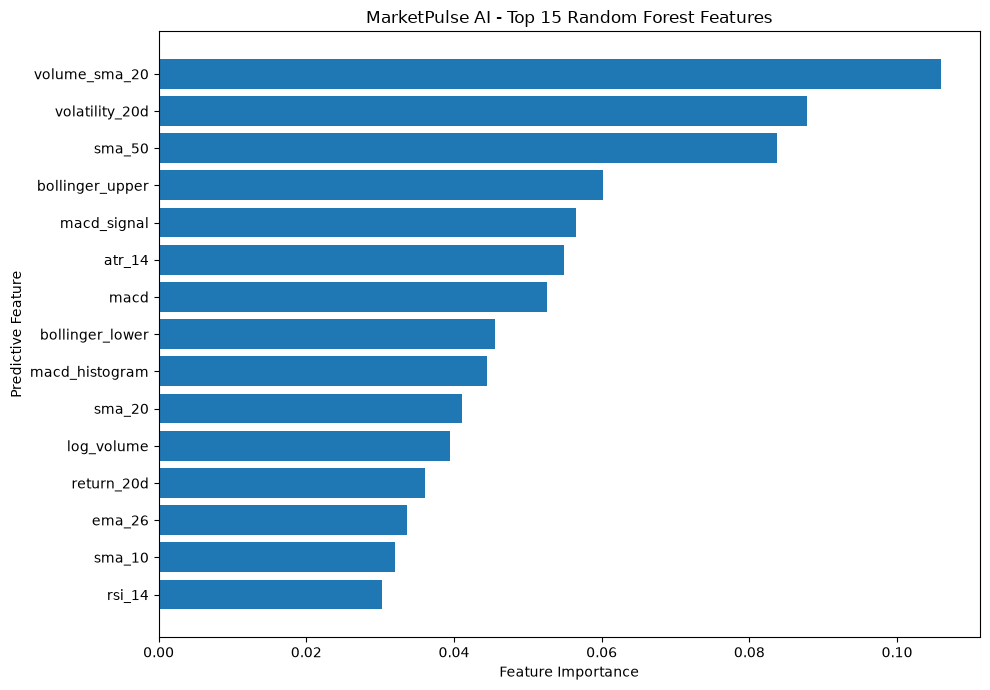


Final model feature verification: PASSED
Test dataset evaluated: NO


In [14]:

# Cell 12 - Final Model Selection and Feature Importance

import matplotlib.pyplot as plt

# Lock selected model and feature set
final_clf_model = best_market_model
final_feature_columns = market_features.copy()

print("MARKETPULSE AI - FINAL CLASSIFIER SELECTION")
print("-" * 50)

print("Model: Random Forest Classifier")
print("Number of features:", len(final_feature_columns))
print("Max depth:", final_clf_model.max_depth)
print("Minimum samples per leaf:",
      final_clf_model.min_samples_leaf)
print("Number of trees:",
      final_clf_model.n_estimators)

print("\nValidation ROC AUC:",
      round(best_market_config["ROC_AUC"], 6))

# Feature importance
importance_df = pd.DataFrame({
    "Feature": final_feature_columns,
    "Importance": final_clf_model.feature_importances_
}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("\nTOP 15 FEATURE IMPORTANCES")
display(importance_df.head(15).round(4))

# Plot feature importance
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("MarketPulse AI - Top 15 Random Forest Features")
plt.xlabel("Feature Importance")
plt.ylabel("Predictive Feature")
plt.tight_layout()
plt.show()

# Verify final model inputs
assert len(final_feature_columns) == 24
assert list(final_clf_model.feature_names_in_) == final_feature_columns

print("\nFinal model feature verification: PASSED")
print("Test dataset evaluated: NO")


In [15]:

# Cell 13 - Validation Probability Analysis

# Generate probabilities from selected market-only model
val_probabilities = final_clf_model.predict_proba(
    X_val[final_feature_columns]
)[:, 1]

# Create validation analysis dataset
validation_analysis = training_df.loc[val_mask, [
    "date",
    "ticker",
    "target_return_10d",
    "target_direction_10d"
]].copy()

validation_analysis["predicted_probability"] = (
    val_probabilities
)

validation_analysis = validation_analysis.reset_index(drop=True)

print("MARKETPULSE AI - VALIDATION PROBABILITY ANALYSIS")
print("-" * 50)

print("\nProbability distribution:")
display(
    validation_analysis["predicted_probability"].describe()
)

print("\nAverage probability by actual outcome:")
display(
    validation_analysis.groupby(
        "target_direction_10d"
    )["predicted_probability"].agg(
        ["count", "mean", "median", "std"]
    ).round(4)
)

# Evaluate different probability thresholds
threshold_results = []

for threshold in [0.50, 0.55, 0.60, 0.65, 0.70]:

    signals = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Selected_Stocks": int(signals.sum()),
        "Selection_Rate": signals.mean(),
        "Precision": precision_score(
            y_val_clf, signals,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_clf, signals,
            zero_division=0
        ),
        "F1": f1_score(
            y_val_clf, signals,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nVALIDATION THRESHOLD COMPARISON")
display(threshold_df.round(4))

print("\nValidation ROC AUC:",
      round(
          roc_auc_score(
              y_val_clf, val_probabilities
          ),
          6
      ))

print("\nValidation records:",
      len(validation_analysis))

print("Test dataset evaluated: NO")


MARKETPULSE AI - VALIDATION PROBABILITY ANALYSIS
--------------------------------------------------

Probability distribution:


count    6200.000000
mean        0.572786
std         0.060059
min         0.378250
25%         0.532027
50%         0.573180
75%         0.615183
max         0.759026
Name: predicted_probability, dtype: float64


Average probability by actual outcome:


,count,mean,median,std
target_direction_10d,,,,
0,2569,0.5663,0.5638,0.0579
1,3631,0.5774,0.5787,0.0611



VALIDATION THRESHOLD COMPARISON


,Threshold,Selected_Stocks,Selection_Rate,Precision,Recall,F1
0,0.50,5493,0.8860,0.5891,0.8912,0.7093
1,0.55,4014,0.6474,0.6148,0.6797,0.6457
2,0.60,2070,0.3339,0.6338,0.3613,0.4603
3,0.65,627,0.1011,0.6954,0.1201,0.2048
4,0.70,80,0.0129,0.8000,0.0176,0.0345



Validation ROC AUC: 0.553643

Validation records: 6200
Test dataset evaluated: NO


In [16]:

# Cell 14 - Validation Trading-Signal Return Analysis

signal_return_results = []

for threshold in [0.50, 0.55, 0.60, 0.65, 0.70]:

    selected = validation_analysis[
        validation_analysis["predicted_probability"] >= threshold
    ]

    returns = selected["target_return_10d"]

    signal_return_results.append({
        "Threshold": threshold,
        "Signals": len(selected),
        "Mean_Return": returns.mean(),
        "Median_Return": returns.median(),
        "Return_Std": returns.std(),
        "Positive_Rate": (returns > 0).mean(),
        "Worst_Return": returns.min(),
        "Best_Return": returns.max()
    })

signal_returns_df = pd.DataFrame(signal_return_results)

print("VALIDATION TRADING-SIGNAL RETURN ANALYSIS")
print("-" * 50)

display(signal_returns_df.round(4))

# Compare with all validation observations
overall_mean_return = validation_analysis[
    "target_return_10d"
].mean()

print("\nALL VALIDATION OBSERVATIONS")
print("Mean 10-day return:",
      round(overall_mean_return, 6))

print("Positive outcome rate:",
      round(
          (
              validation_analysis[
                  "target_return_10d"
              ] > 0
          ).mean(),
          4
      ))

print("\nTHRESHOLD 0.60 SUMMARY")

selected_060 = validation_analysis[
    validation_analysis["predicted_probability"] >= 0.60
]

print("Selected observations:", len(selected_060))

print("Average 10-day return:",
      round(
          selected_060["target_return_10d"].mean(),
          6
      ))

print("Median 10-day return:",
      round(
          selected_060["target_return_10d"].median(),
          6
      ))

print("Positive outcome rate:",
      round(
          (
              selected_060["target_return_10d"] > 0
          ).mean(),
          4
      ))

print("\nTest dataset evaluated: NO")


VALIDATION TRADING-SIGNAL RETURN ANALYSIS
--------------------------------------------------


,Threshold,Signals,Mean_Return,Median_Return,Return_Std,Positive_Rate,Worst_Return,Best_Return
0,0.50,5493,0.0105,0.0119,0.0603,0.5891,-0.3153,0.2992
1,0.55,4014,0.0129,0.0146,0.0606,0.6148,-0.3153,0.2992
2,0.60,2070,0.0150,0.0170,0.0626,0.6338,-0.3153,0.2992
3,0.65,627,0.0183,0.0223,0.0728,0.6954,-0.3153,0.2992
4,0.70,80,0.0233,0.0298,0.0815,0.8000,-0.3153,0.2350



ALL VALIDATION OBSERVATIONS
Mean 10-day return: 0.009863
Positive outcome rate: 0.5856

THRESHOLD 0.60 SUMMARY
Selected observations: 2070
Average 10-day return: 0.015043
Median 10-day return: 0.017033
Positive outcome rate: 0.6338

Test dataset evaluated: NO


In [17]:

# Cell 15 - Lock Trading Configuration

import json

# Selected configuration based on validation results
trading_config = {
    "project": "MarketPulse AI",
    "model_type": "RandomForestClassifier",
    "feature_set": "market_only",
    "feature_count": len(final_feature_columns),
    "features": final_feature_columns,
    "n_estimators": final_clf_model.n_estimators,
    "max_depth": final_clf_model.max_depth,
    "min_samples_leaf": final_clf_model.min_samples_leaf,
    "max_features": final_clf_model.max_features,
    "random_state": 42,
    "prediction_horizon_days": 10,
    "signal_threshold": 0.60,
    "signal_timing": "after_market_close",
    "execution_timing": "next_trading_session",
    "validation_roc_auc": float(
        best_market_config["ROC_AUC"]
    ),
    "validation_mean_signal_return": float(
        selected_060["target_return_10d"].mean()
    ),
    "test_evaluated": False
}

print("MARKETPULSE AI - LOCKED TRADING CONFIGURATION")
print("-" * 50)

print(json.dumps(trading_config, indent=2))

# Verify configuration
assert trading_config["feature_count"] == 24
assert trading_config["signal_threshold"] == 0.60
assert trading_config["test_evaluated"] is False

print("\nTrading configuration verification: PASSED")
print("Test dataset evaluated: NO")


MARKETPULSE AI - LOCKED TRADING CONFIGURATION
--------------------------------------------------
{
  "project": "MarketPulse AI",
  "model_type": "RandomForestClassifier",
  "feature_set": "market_only",
  "feature_count": 24,
  "features": [
    "return_1d",
    "return_5d",
    "return_10d",
    "return_20d",
    "sma_5",
    "sma_10",
    "sma_20",
    "sma_50",
    "ema_12",
    "ema_26",
    "volatility_5d",
    "volatility_20d",
    "daily_range_pct",
    "atr_14",
    "rsi_14",
    "macd",
    "macd_signal",
    "macd_histogram",
    "bollinger_upper",
    "bollinger_lower",
    "volume_change_1d",
    "volume_sma_20",
    "relative_volume_20",
    "log_volume"
  ],
  "n_estimators": 100,
  "max_depth": 15,
  "min_samples_leaf": 100,
  "max_features": 0.7,
  "random_state": 42,
  "prediction_horizon_days": 10,
  "signal_threshold": 0.6,
  "signal_timing": "after_market_close",
  "execution_timing": "next_trading_session",
  "validation_roc_auc": 0.5536431612260626,
  "validation

In [18]:

# Cell 16 - Final Out-of-Sample Test Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Prepare test features using the locked feature list
X_test_final = X_test[final_feature_columns].copy()

# Use the previously selected, trained model
test_probabilities = final_clf_model.predict_proba(
    X_test_final
)[:, 1]

# Apply the locked threshold
test_predictions = (
    test_probabilities >= trading_config["signal_threshold"]
).astype(int)

# Classification metrics
test_accuracy = accuracy_score(
    y_test_clf, test_predictions
)

test_precision = precision_score(
    y_test_clf, test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test_clf, test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test_clf, test_predictions,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test_clf, test_probabilities
)

# Build test analysis table
test_analysis = training_df.loc[test_mask, [
    "date",
    "ticker",
    "target_return_10d",
    "target_direction_10d"
]].copy()

test_analysis["predicted_probability"] = test_probabilities
test_analysis["signal"] = test_predictions

test_analysis = test_analysis.reset_index(drop=True)

# Selected observations
selected_test = test_analysis[
    test_analysis["signal"] == 1
]

print("MARKETPULSE AI - OUT-OF-SAMPLE TEST EVALUATION")
print("-" * 50)

print("\nTEST PERIOD")
print("Start:", test_analysis["date"].min())
print("End:  ", test_analysis["date"].max())
print("Observations:", len(test_analysis))

print("\nCLASSIFICATION PERFORMANCE")
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1:", round(test_f1, 4))
print("ROC AUC:", round(test_auc, 4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test_clf, test_predictions))

print("\nTRADING SIGNAL SUMMARY")
print("Threshold:", trading_config["signal_threshold"])
print("Selected observations:", len(selected_test))
print("Selection rate:",
      round(len(selected_test) / len(test_analysis), 4))

print("Mean 10-day forward return:",
      round(selected_test["target_return_10d"].mean(), 6))

print("Median 10-day forward return:",
      round(selected_test["target_return_10d"].median(), 6))

print("Positive outcome rate:",
      round(
          (selected_test["target_return_10d"] > 0).mean(),
          4
      ))

print("\nALL TEST OBSERVATIONS")
print("Mean 10-day forward return:",
      round(test_analysis["target_return_10d"].mean(), 6))

print("Positive outcome rate:",
      round((test_analysis["target_return_10d"] > 0).mean(), 4))

print("\nValidation ROC AUC:",
      round(best_market_config["ROC_AUC"], 4))
print("Test ROC AUC:", round(test_auc, 4))

# Mark test evaluation complete
trading_config["test_evaluated"] = True

print("\nTest evaluation completed: YES")


MARKETPULSE AI - OUT-OF-SAMPLE TEST EVALUATION
--------------------------------------------------

TEST PERIOD
Start: 2025-07-16 00:00:00
End:   2026-10-21 00:00:00
Observations: 6400

CLASSIFICATION PERFORMANCE
Accuracy: 0.4973
Precision: 0.5623
Recall: 0.3376
F1: 0.4219
ROC AUC: 0.5125

CONFUSION MATRIX
[[2009  914]
 [2303 1174]]

TRADING SIGNAL SUMMARY
Threshold: 0.6
Selected observations: 2088
Selection rate: 0.3262
Mean 10-day forward return: 0.011004
Median 10-day forward return: 0.007305
Positive outcome rate: 0.5623

ALL TEST OBSERVATIONS
Mean 10-day forward return: 0.008069
Positive outcome rate: 0.5433

Validation ROC AUC: 0.5536
Test ROC AUC: 0.5125

Test evaluation completed: YES


In [19]:

# Cell 17 - Save Final Model, Configuration, and Predictions

import joblib
import json
from pathlib import Path

# Project directories
models_dir = project_root / "models"
results_dir = project_root / "results"

models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Save selected trained model
model_path = models_dir / "marketpulse_rf_market_only.joblib"

joblib.dump(final_clf_model, model_path)

# Save locked configuration
config_path = models_dir / "marketpulse_trading_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(trading_config, f, indent=2)

# Save test predictions
predictions_path = results_dir / "marketpulse_test_predictions.parquet"

test_analysis.to_parquet(
    predictions_path,
    index=False
)

# Save model comparison tables
reg_comparison.to_csv(
    results_dir / "regression_model_comparison.csv",
    index=False
)

clf_comparison.to_csv(
    results_dir / "classification_model_comparison.csv",
    index=False
)

# Save market-only tuning results
market_rf_tuning_df.to_csv(
    results_dir / "market_only_rf_tuning.csv",
    index=False
)

print("MARKETPULSE AI - MODEL ARTIFACTS")
print("-" * 50)

for path in [
    model_path,
    config_path,
    predictions_path,
    results_dir / "regression_model_comparison.csv",
    results_dir / "classification_model_comparison.csv",
    results_dir / "market_only_rf_tuning.csv"
]:
    print(f"{path.name}: {'SAVED' if path.exists() else 'MISSING'}")

# Verify saved model
loaded_model = joblib.load(model_path)

assert list(loaded_model.feature_names_in_) == final_feature_columns
assert loaded_model.max_depth == 15
assert loaded_model.min_samples_leaf == 100

# Verify saved predictions
loaded_predictions = pd.read_parquet(predictions_path)

assert len(loaded_predictions) == len(test_analysis)
assert loaded_predictions["signal"].sum() == 2088

print("\nSaved model verification: PASSED")
print("Saved predictions verification: PASSED")
print("Notebook 03 artifacts ready for backtesting.")


MARKETPULSE AI - MODEL ARTIFACTS
--------------------------------------------------
marketpulse_rf_market_only.joblib: SAVED
marketpulse_trading_config.json: SAVED
marketpulse_test_predictions.parquet: SAVED
regression_model_comparison.csv: SAVED
classification_model_comparison.csv: SAVED
market_only_rf_tuning.csv: SAVED

Saved model verification: PASSED
Saved predictions verification: PASSED
Notebook 03 artifacts ready for backtesting.
